# 50. Air-to-ground coupling at each site

At every site with a pressure sensor and a vertical seismic sensor side by side, this notebook
measures how strongly the launch pressure field drives ground motion:

* **coupling coefficients** (vertical velocity per pressure, µm s⁻¹ Pa⁻¹): RMS ratio, peak ratio and
  a least-squares regression coefficient *v = k p* at the best lag (its **sign** gives the polarity);
* the **transfer function** H(f) = P_pv / P_pp, **coherence** and **phase** (Welch, masked);
* how the coupling **changes with time** during the launch (5-s windows), i.e. as the source climbs
  and the angle of incidence steepens.

Pairs: Centaur infraBSU `CD0` + Trillium `CHZ` (B01, B03, B05, B29; 500 sps) and Gem `HD?` + SmartSolo
`DPZ` (100 sps). Both members are taken to a common rate. Gem overflow intervals (notebook 20) are
masked: Welch segments that touch them are skipped and time-domain metrics use unmasked samples only.

Caveats: B03's Centaur channels are ~100x low (hardware); B05's Trillium mass is off-centre (CH1/CH2
near full scale, notebook 20), so only its CHZ is used and only above 1 Hz; SmartSolo responses are
nominal.

Outputs (`cfg.OUT_DIR`): `coupling_metrics.csv`, `coupling_transfer_functions.csv`,
`coupling_vs_time.csv`, `coupling_transfer_functions.png`, `coupling_summary.png`,
`coupling_vs_time.png`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import get_window

import artemis2_config as cfg

L = cfg.LAUNCHTIME
OUT = cfg.OUT_DIR / "50_air_ground_coupling"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.grid': True, 'grid.color': '#dddddd', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False})

SIGNAL = (L, L + 180)          # launch window
NOISE = (L - 900, L - 720)     # same length, pre-launch
BAND = (1.0, 40.0)             # Hz, common band for time-domain metrics (all pairs)
SEG_S = 4.0                    # Welch segment, s
COH_MIN = 0.5
MAXLAG_S = 0.5
SUMMARY_BANDS = [(1, 5), (5, 20), (20, 40)]
stations = cfg.station_table()

PAIRS = [  # (pressure, vertical velocity, pair type)
    ('1R.B01.00.CD0', '1R.B01.00.CHZ', 'infraBSU-Trillium'),
    ('1R.B03.00.CD0', '1R.B03.00.CHZ', 'infraBSU-Trillium'),
    ('1R.B05.00.CD0', '1R.B05.00.CHZ', 'infraBSU-Trillium'),
    ('1R.B29.00.CD0', '1R.B29.00.CHZ', 'infraBSU-Trillium'),
    ('1R.B01.00.CD0', '1R.B01..DPZ', 'infraBSU-SmartSolo'),
    ('1R.B01..HDI', '1R.B01..DPZ', 'Gem-SmartSolo'),
    ('1R.B03..HDI', '1R.B03..DPZ', 'Gem-SmartSolo'),
    ('1R.B07..HDF', '1R.B07..DPZ', 'Gem-SmartSolo'),
    ('1R.B12..HDF', '1R.B12..DPZ', 'Gem-SmartSolo'),
    ('1R.B14..HDF', '1R.B14..DPZ', 'Gem-SmartSolo'),
    ('1R.B20..HDF', '1R.B20..DPZ', 'Gem-SmartSolo'),
    ('1R.B20S..HDF', '1R.B20S..DPZ', 'Gem-SmartSolo'),
    ('1R.B20W..HDF', '1R.B20W..DPZ', 'Gem-SmartSolo'),
    ('1R.B23..HDF', '1R.B23..DPZ', 'Gem-SmartSolo'),
    ('1R.B24..HDF', '1R.B24..DPZ', 'Gem-SmartSolo'),
]

## 1. Data

In [2]:
raw = cfg.launch_stream_raw()
clips = cfg.stream_clip_intervals(raw)
st = cfg.instrument_correct(raw)
for tr in st:   # SmartSolo files carry location "--"; normalise to "" so IDs match PAIRS
    if tr.stats.location == '--':
        tr.stats.location = ''
ids = {tr.id for tr in st}
print('missing:', sorted({x for p in PAIRS for x in p[:2]} - ids))

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/ksclib/src/ksclib/data.py:34: UserWarning: SKIPPED unreadable SDS file /Volumes/KSCGTdownld/SDS/2026/1R/B29/DHZ.D/1R.B29.00.DHZ.D.2026.091 (InternalMSEEDParseTimeError)
  warnings.warn(f"SKIPPED unreadable SDS file {path} ({type(exc).__name__})")


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


... (16 outputs left out)

/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


missing: []


In [3]:
def common_pair(p_id, v_id):
    """Pressure and velocity traces at a common rate (lowest of the two), aligned, plus a mask."""
    p, v = st.select(id=p_id)[0].copy(), st.select(id=v_id)[0].copy()
    fs = min(p.stats.sampling_rate, v.stats.sampling_rate)
    for t in (p, v):
        if t.stats.sampling_rate > fs:
            t.filter('lowpass', freq=0.4 * fs, corners=8, zerophase=True)
            t.resample(fs, no_filter=True)
    t0 = max(p.stats.starttime, v.stats.starttime); t1 = min(p.stats.endtime, v.stats.endtime)
    for t in (p, v):
        t.trim(t0, t1, nearest_sample=True)
    n = min(p.stats.npts, v.stats.npts)
    p.data, v.data = p.data[:n].astype(float), v.data[:n].astype(float)
    mask = cfg.clip_mask(p, clips.get(p_id, []))
    return p, v, mask, fs

def masked_welch(x, y, mask, fs, seg_s=SEG_S):
    """Welch auto/cross spectra using only segments that contain no masked sample."""
    n = int(seg_s * fs); step = n // 2
    w = get_window('hann', n); scale = 1.0 / (fs * (w ** 2).sum())
    sxx = syy = sxy = 0; k = 0
    for i in range(0, len(x) - n + 1, step):
        if mask[i:i + n].any():
            continue
        X = np.fft.rfft(w * (x[i:i + n] - x[i:i + n].mean()))
        Y = np.fft.rfft(w * (y[i:i + n] - y[i:i + n].mean()))
        sxx = sxx + np.abs(X) ** 2; syy = syy + np.abs(Y) ** 2; sxy = sxy + np.conj(X) * Y; k += 1
    f = np.fft.rfftfreq(n, 1 / fs)
    if k == 0:
        return f, None
    return f, dict(pxx=scale * sxx / k, pyy=scale * syy / k, pxy=scale * sxy / k, nseg=k)

def window_idx(tr, win):
    t = tr.stats.starttime.timestamp + tr.times()
    return (t >= win[0].timestamp) & (t < win[1].timestamp)

def regression(p, v, fs):
    """k minimising |v - k p(t - lag)|^2 over lags within +-MAXLAG_S; returns k, lag (s), correlation."""
    best = (0, 0, 0)
    m = int(MAXLAG_S * fs)
    for lag in range(-m, m + 1):
        if lag >= 0:
            a, b = p[:len(p) - lag], v[lag:]
        else:
            a, b = p[-lag:], v[:len(v) + lag]
        r = np.corrcoef(a, b)[0, 1]
        if abs(r) > abs(best[2]):
            best = (np.dot(a, b) / np.dot(a, a), lag / fs, r)
    return best

## 2. Coupling coefficients and transfer functions

In [4]:
rows, tf_rows, tfs = [], [], {}
for p_id, v_id, kind in PAIRS:
    if p_id not in ids or v_id not in ids:
        continue
    p, v, mask, fs = common_pair(p_id, v_id)
    sta = p.stats.station
    pb, vb = p.copy(), v.copy()
    for t in (pb, vb):
        t.filter('bandpass', freqmin=BAND[0], freqmax=BAND[1], corners=4, zerophase=True)
    sig = window_idx(p, SIGNAL) & ~mask
    noi = window_idx(p, NOISE)
    k, lag, r = regression(pb.data[sig], vb.data[sig], fs)
    row = dict(pair=f"{p_id.replace('1R.', '')} / {v_id.replace('1R.', '')}", pressure=p_id, velocity=v_id,
               kind=kind, station=sta, distance_km=stations.distance_km.get(sta, np.nan), fs=fs,
               masked_s=mask[window_idx(p, SIGNAL)].sum() / fs,
               peak_p_Pa=np.abs(pb.data[sig]).max(), peak_v_mps=np.abs(vb.data[sig]).max(),
               k_peak_um_s_Pa=1e6 * np.abs(vb.data[sig]).max() / np.abs(pb.data[sig]).max(),
               k_rms_um_s_Pa=1e6 * vb.data[sig].std() / pb.data[sig].std(),
               k_regression_um_s_Pa=1e6 * k, lag_s=lag, corr=r,
               noise_k_rms_um_s_Pa=1e6 * vb.data[noi].std() / pb.data[noi].std())
    f, sp = masked_welch(p.data[window_idx(p, SIGNAL)], v.data[window_idx(p, SIGNAL)],
                         mask[window_idx(p, SIGNAL)], fs)
    if sp is not None:
        H = sp['pxy'] / sp['pxx']
        coh = np.abs(sp['pxy']) ** 2 / (sp['pxx'] * sp['pyy'])
        tfs[row['pair']] = dict(f=f, H=H, coh=coh, kind=kind, dist=row['distance_km'])
        row['n_segments'] = sp['nseg']
        for lo, hi in SUMMARY_BANDS:
            m = (f >= lo) & (f < hi) & (coh >= COH_MIN)
            row[f'H_{lo}-{hi}Hz_um_s_Pa'] = 1e6 * np.median(np.abs(H[m])) if m.any() else np.nan
            row[f'coh_{lo}-{hi}Hz'] = np.median(coh[(f >= lo) & (f < hi)])
            row[f'phase_{lo}-{hi}Hz_deg'] = np.degrees(np.angle(np.median(H[m] / np.abs(H[m])))) if m.any() else np.nan
        for fi, h, c in zip(f, H, coh):
            if 0.5 <= fi <= 0.45 * fs:
                tf_rows.append(dict(pair=row['pair'], f_hz=fi, H_abs_um_s_Pa=1e6 * abs(h),
                                    phase_deg=np.degrees(np.angle(h)), coherence=c))
    rows.append(row)

coup = pd.DataFrame(rows)
coup.to_csv(OUT / 'coupling_metrics.csv', index=False)
pd.DataFrame(tf_rows).to_csv(OUT / 'coupling_transfer_functions.csv', index=False)
cols = ['pair', 'kind', 'distance_km', 'masked_s', 'k_rms_um_s_Pa', 'k_peak_um_s_Pa', 'k_regression_um_s_Pa',
        'corr', 'lag_s', 'noise_k_rms_um_s_Pa'] + [c for c in coup.columns if c.startswith(('H_', 'coh_', 'phase_'))]
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.width', 250):
    display(coup[cols].sort_values('distance_km'))

,pair,kind,distance_km,masked_s,k_rms_um_s_Pa,k_peak_um_s_Pa,k_regression_um_s_Pa,corr,lag_s,noise_k_rms_um_s_Pa,H_1-5Hz_um_s_Pa,coh_1-5Hz,phase_1-5Hz_deg,H_5-20Hz_um_s_Pa,coh_5-20Hz,phase_5-20Hz_deg,H_20-40Hz_um_s_Pa,coh_20-40Hz,phase_20-40Hz_deg
9,B14..HDF / B14..DPZ,Gem-SmartSolo,0.739,28.6,4.54,6.88,1.27,0.281,-0.01,37.2,0.721,0.198,48.6,2.15,0.714,70.9,8.24,0.413,-47.7
0,B01.00.CD0 / B01.00.CHZ,infraBSU-Trillium,1.53,0,7.51,9.02,-2.64,-0.351,0.004,60.9,0.579,0.196,-92.1,5.05,0.3,-170,7.05,0.319,134
4,B01.00.CD0 / B01..DPZ,infraBSU-SmartSolo,1.53,0,7.54,8.94,2.66,0.352,0.004,61.3,NaN,0.19,NaN,5.34,0.317,13.3,7.12,0.305,-60.2
5,B01..HDI / B01..DPZ,Gem-SmartSolo,1.53,22.6,5.15,9.55,1.45,0.281,-0.01,63.7,0.592,0.162,75.6,3.77,0.27,81.5,5.54,0.507,33.9
1,B03.00.CD0 / B03.00.CHZ,infraBSU-Trillium,1.75,0,54.7,110,5.04,0.0921,0.362,1.54,NaN,0.0357,NaN,NaN,0.103,NaN,NaN,0.0942,NaN
6,B03..HDI / B03..DPZ,Gem-SmartSolo,1.75,14.4,6.86,6.83,-1.44,-0.211,0.12,15.9,1.3,0.348,80.6,2.82,0.163,62.6,3.53,0.567,29.2
8,B12..HDF / B12..DPZ,Gem-SmartSolo,2.65,13.6,9.5,10.6,3.18,0.334,0,2.22,NaN,0.305,NaN,11.5,0.412,17.6,6.43,0.595,55.1
2,B05.00.CD0 / B05.00.CHZ,infraBSU-Trillium,2.76,0,3.2,4.69,0.775,0.242,0.044,10.9,NaN,0.0519,NaN,1.63,0.26,109,2.38,0.642,-109
7,B07..HDF / B07..DPZ,Gem-SmartSolo,3.42,0,6,5.64,1.41,0.236,0.02,54,NaN,0.0966,NaN,2.02,0.356,-123,1.52,0.377,137
14,B24..HDF / B24..DPZ,Gem-SmartSolo,5.53,0,7.48,5.81,2.15,0.287,0,12.4,NaN,0.255,NaN,5.31,0.504,-31.4,5.98,0.496,39.6


### Polarity

For local loading of the ground by the air wave, positive (compressive) pressure pushes the surface
down, so with "up = positive" the regression coefficient should be **negative**.

In [5]:
for kind, g in coup.groupby('kind'):
    print(f"{kind:20s} regression sign: {', '.join(f'{s}:{np.sign(k):+.0f}' for s, k in zip(g.station, g.k_regression_um_s_Pa))}")

Gem-SmartSolo        regression sign: B01:+1, B03:-1, B07:+1, B12:+1, B14:+1, B20:+1, B20S:+1, B20W:+1, B23:+1, B24:+1
infraBSU-SmartSolo   regression sign: B01:+1
infraBSU-Trillium    regression sign: B01:-1, B03:+1, B05:+1, B29:-1


## 3. Coupling through time

In [6]:
WIN = 5.0
trows = []
for p_id, v_id, kind in PAIRS:
    if p_id not in ids or v_id not in ids:
        continue
    p, v, mask, fs = common_pair(p_id, v_id)
    for t in (p, v):
        t.filter('bandpass', freqmin=BAND[0], freqmax=BAND[1], corners=4, zerophase=True)
    for t0 in np.arange(0, 180, WIN):
        idx = window_idx(p, (L + t0, L + t0 + WIN))
        if mask[idx].any():
            continue
        a, b = p.data[idx], v.data[idx]
        trows.append(dict(pair=f"{p_id.replace('1R.', '')} / {v_id.replace('1R.', '')}", kind=kind,
                          t_mid=t0 + WIN / 2, k_rms_um_s_Pa=1e6 * b.std() / a.std(),
                          corr=np.corrcoef(a, b)[0, 1], p_rms=a.std()))
ktime = pd.DataFrame(trows)
ktime.to_csv(OUT / 'coupling_vs_time.csv', index=False)

## 4. Figures

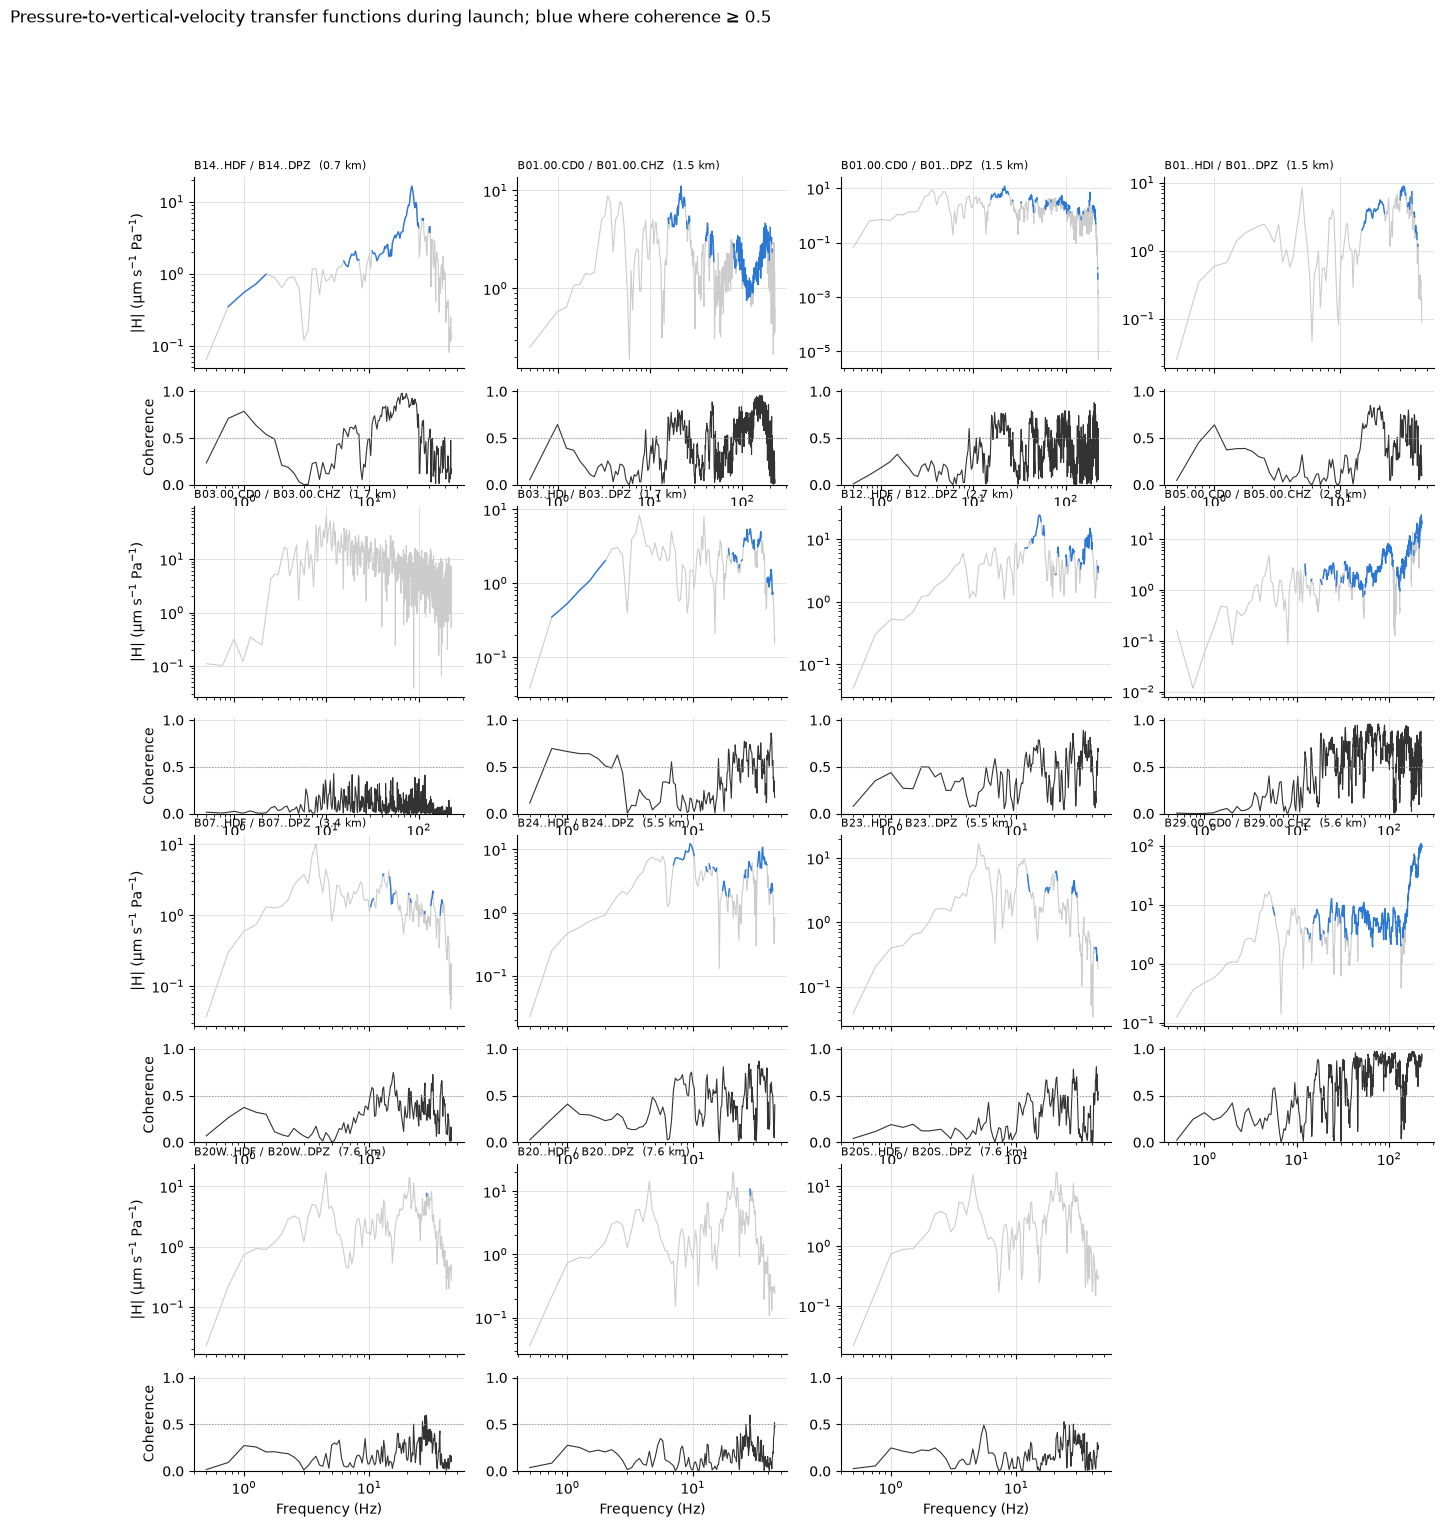

In [7]:
pairs_sorted = coup.sort_values('distance_km').pair.tolist()
pairs_sorted = [p for p in pairs_sorted if p in tfs]
ncol = 4
nrow = int(np.ceil(len(pairs_sorted) / ncol))
fig = plt.figure(figsize=(16, 4.2 * nrow))
gs = fig.add_gridspec(2 * nrow, ncol, height_ratios=[2, 1] * nrow, hspace=0.15)
for i, pair in enumerate(pairs_sorted):
    r, c = divmod(i, ncol)
    a1 = fig.add_subplot(gs[2 * r, c]); a2 = fig.add_subplot(gs[2 * r + 1, c], sharex=a1)
    d = tfs[pair]; f = d['f']; m = (f >= 0.5) & (f <= 0.45 * coup.set_index('pair').loc[pair, 'fs'])
    good = m & (d['coh'] >= COH_MIN)
    a1.loglog(f[m], 1e6 * np.abs(d['H'][m]), color='#cccccc', lw=0.8)
    a1.loglog(np.where(good, f, np.nan), np.where(good, 1e6 * np.abs(d['H']), np.nan), color='#2a78d6', lw=1)
    a1.set_title(f"{pair}  ({d['dist']:.1f} km)", fontsize=8, loc='left')
    a2.semilogx(f[m], d['coh'][m], color='#333333', lw=0.8)
    a2.axhline(COH_MIN, color='#999999', ls=':', lw=0.8)
    a2.set_ylim(0, 1.02)
    plt.setp(a1.get_xticklabels(), visible=False)
    if c == 0:
        a1.set_ylabel('|H| (µm s$^{-1}$ Pa$^{-1}$)'); a2.set_ylabel('Coherence')
    if r == nrow - 1:
        a2.set_xlabel('Frequency (Hz)')
fig.suptitle(f'Pressure-to-vertical-velocity transfer functions during launch; blue where coherence ≥ {COH_MIN}',
             x=0.01, ha='left')
fig.savefig(OUT / 'coupling_transfer_functions.png', dpi=200, bbox_inches='tight')

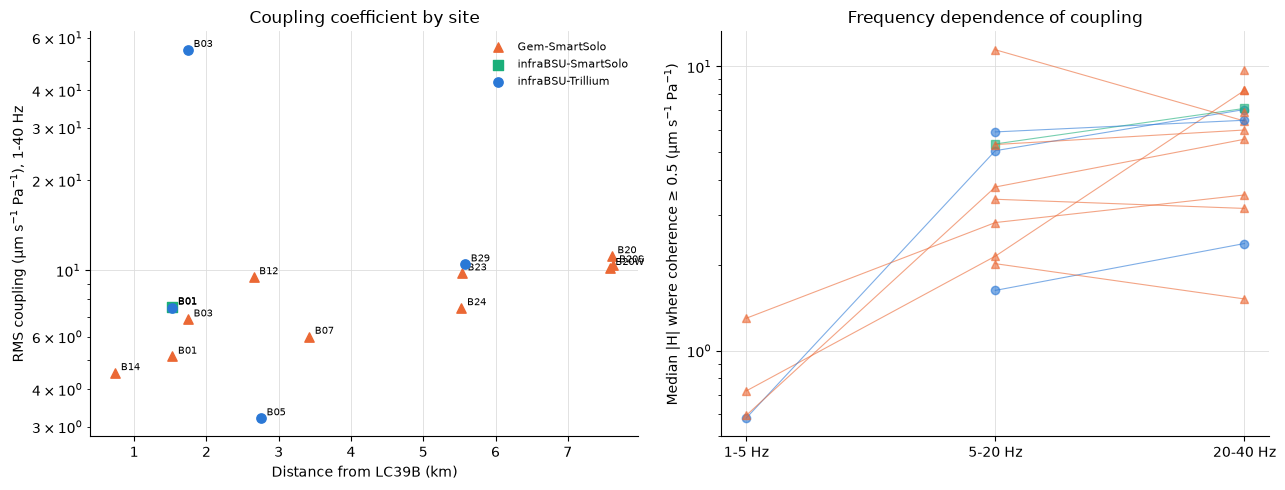

In [8]:
MARK = {'infraBSU-Trillium': ('o', '#2a78d6'), 'infraBSU-SmartSolo': ('s', '#1baf7a'), 'Gem-SmartSolo': ('^', '#eb6834')}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for kind, g in coup.groupby('kind'):
    mk, col = MARK[kind]
    ax[0].scatter(g.distance_km, g.k_rms_um_s_Pa, marker=mk, color=col, s=45, label=kind, zorder=3)
    for _, r in g.iterrows():
        ax[0].annotate(r.station, (r.distance_km, r.k_rms_um_s_Pa), fontsize=7, xytext=(4, 2),
                       textcoords='offset points')
ax[0].set(yscale='log', xlabel='Distance from LC39B (km)', ylabel='RMS coupling (µm s$^{-1}$ Pa$^{-1}$), 1-40 Hz',
          title='Coupling coefficient by site')
ax[0].legend(frameon=False, fontsize=8)
band_cols = [f'H_{lo}-{hi}Hz_um_s_Pa' for lo, hi in SUMMARY_BANDS]
xs = np.arange(len(SUMMARY_BANDS))
for _, r in coup.sort_values('distance_km').iterrows():
    mk, col = MARK[r.kind]
    ax[1].plot(xs, r[band_cols].astype(float), marker=mk, color=col, alpha=0.6, lw=0.8)
ax[1].set_xticks(xs); ax[1].set_xticklabels([f'{lo}-{hi} Hz' for lo, hi in SUMMARY_BANDS])
ax[1].set(yscale='log', ylabel='Median |H| where coherence ≥ 0.5 (µm s$^{-1}$ Pa$^{-1}$)',
          title='Frequency dependence of coupling')
fig.tight_layout()
fig.savefig(OUT / 'coupling_summary.png', dpi=200)

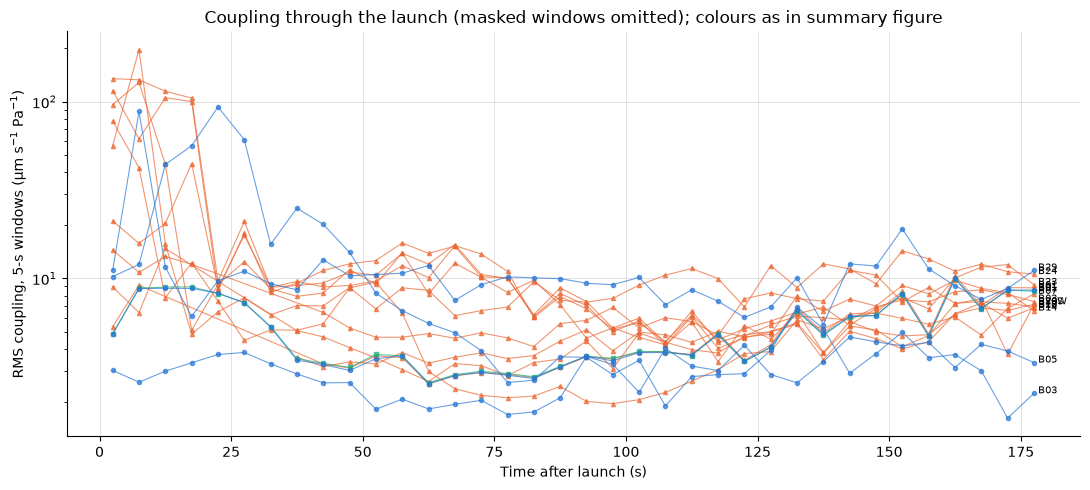

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
for kind, g in ktime.groupby('kind'):
    mk, col = MARK[kind]
    for pair, h in g.groupby('pair'):
        ax.plot(h.t_mid, h.k_rms_um_s_Pa, marker=mk, ms=3, lw=0.8, color=col, alpha=0.7)
        ax.annotate(pair.split('.')[0], (h.t_mid.iloc[-1], h.k_rms_um_s_Pa.iloc[-1]), fontsize=7,
                    xytext=(3, 0), textcoords='offset points')
ax.set(yscale='log', xlabel='Time after launch (s)', ylabel='RMS coupling, 5-s windows (µm s$^{-1}$ Pa$^{-1}$)',
       title='Coupling through the launch (masked windows omitted); colours as in summary figure')
fig.tight_layout()
fig.savefig(OUT / 'coupling_vs_time.png', dpi=200)